# 1. CONTOURS 

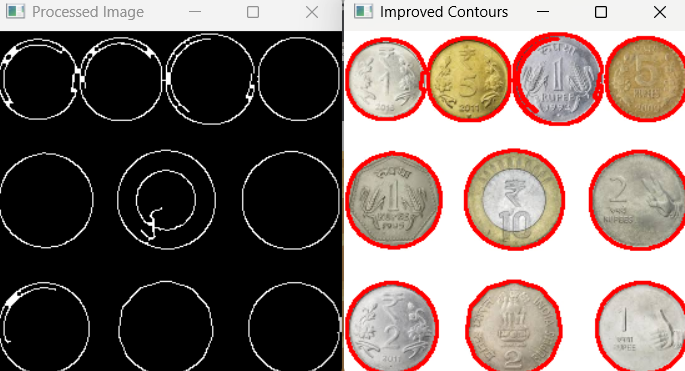

In [1]:
import cv2 as cv 

image=cv.imread("IMAGES/iphone2.png")
image=cv.resize(image , None , fx=0.5 , fy=0.5  , interpolation=cv.INTER_AREA)

gray=cv.cvtColor(image , cv.COLOR_BGR2GRAY)
blurred=cv.bilateralFilter(gray, 9 , 75 ,75)

edges=cv.Canny(blurred , 50 , 150 )
kernel=cv.getStructuringElement(cv.MORPH_RECT , (3,3))
closed_edges=cv.morphologyEx(edges , cv.MORPH_CLOSE , kernel)

contours , heirarchy = cv.findContours(closed_edges , cv.RETR_EXTERNAL , cv.CHAIN_APPROX_SIMPLE)

result = image.copy()

for cnt in contours:
    area=cv.contourArea(cnt)
    perimeter=cv.arcLength(cnt , True)
    print("PERIMETER: ", perimeter)
    if area > 20:
        cv.drawContours(result , [cnt] , -1 ,  (0,0,255),2)

cv.imshow("Processed Image" , closed_edges)
cv.imshow("Improved Contours", result)

cv.waitKey(0)
cv.destroyAllWindows()

PERIMETER:  59.597978472709656
PERIMETER:  1528.864128947258


# 2. BOUNDING BOXES

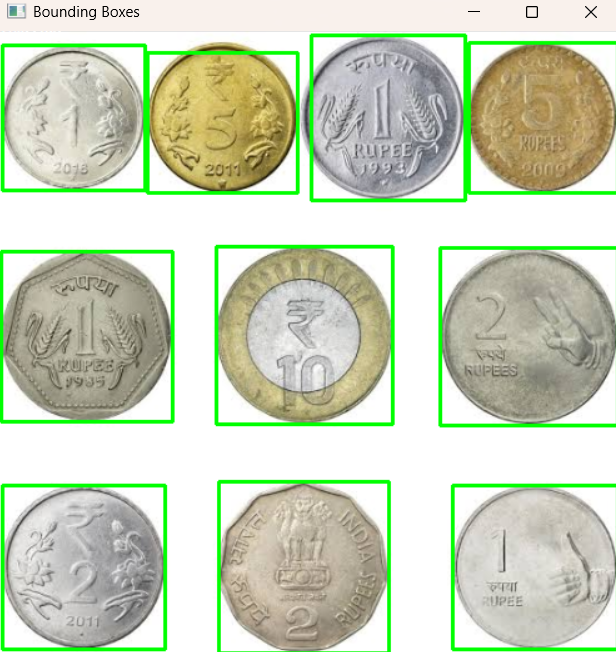

In [82]:
import cv2 as cv

image = cv.imread("IMAGES/coins.png")
image=cv.resize(image , None , fx=0.9 , fy=0.9  , interpolation=cv.INTER_AREA)

gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY)
blurred=cv.bilateralFilter(gray ,9 , 75 , 75)

edges = cv.Canny(blurred, 50, 150)
kernel=cv.getStructuringElement(cv.MORPH_RECT , (3,3))
closed_edges=cv.morphologyEx(edges , cv.MORPH_CLOSE , kernel)

contours, hierarchy = cv.findContours(edges,cv.RETR_EXTERNAL,cv.CHAIN_APPROX_SIMPLE)

for contour in contours:

    area = cv.contourArea(contour)

    # Remove small contours
    if area > 55:

        x, y, w, h = cv.boundingRect(contour)

        cv.rectangle(image,(x, y),(x + w, y + h),(0, 255, 0),2)

cv.imshow("Bounding Boxes", image)

cv.waitKey(0)
cv.destroyAllWindows()

## 3.Shape Detection

In [43]:
import cv2 as cv
image=cv.resize(cv.imread("IMAGES/shapes.png") , None , fx=1 , fy=1 , interpolation=cv.INTER_AREA)

gray=cv.cvtColor(image , cv.COLOR_BGR2GRAY)
blurr=cv.bilateralFilter(gray,9,75,75)
edges=cv.Canny(blurr , 50,150)

kernel=cv.getStructuringElement(cv.MORPH_RECT , (3,3))
closed_edges=cv.morphologyEx(edges , cv.MORPH_CLOSE , kernel)


contours , heirarchy=cv.findContours(closed_edges,  cv.RETR_EXTERNAL , cv.CHAIN_APPROX_SIMPLE)
for contour in contours:
    perimeter = cv.arcLength(contour, True)

    approx = cv.approxPolyDP(
        contour, 0.01 * perimeter, True
    )

    vertices = len(approx)
    
    if vertices == 3:
        shape = "Triangle"

    elif vertices == 4:
        x, y, w, h = cv.boundingRect(approx)

        ratio = w / float(h)
        if 0.95 <= ratio <= 1.05:
            shape = "Square"
        else:
            shape = "Rectangle"

    elif vertices == 5:
        shape = "Pentagon"

    elif vertices == 6:
        shape = "Hexagon"

    else:
        shape = "Other"

    cv.drawContours(image, [approx], -1, (0, 255, 0), 2)

    x, y, w, h = cv.boundingRect(approx)
    cv.putText(
        image, shape, (x, max(y - 10, 20)),
        cv.FONT_HERSHEY_SIMPLEX, 0.6,
        (0, 0, 255), 2
    )

cv.imshow("Edges", edges)
cv.imshow("Shape Detection", image)

cv.waitKey(0)
cv.destroyAllWindows()

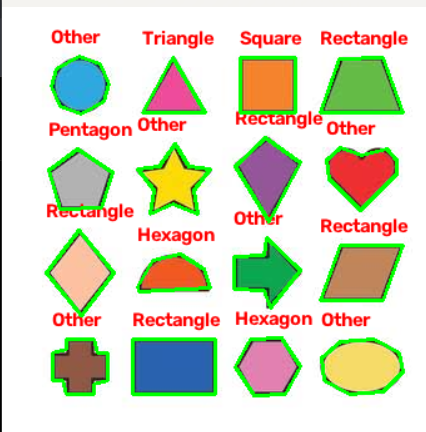

In [1]:

import cv2 as cv

image = cv.imread("IMAGES/shapes.png")
gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY)
edges = cv.Canny(cv.GaussianBlur(gray, (5, 5), 0), 50, 150)

contours, _ = cv.findContours(
    edges, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE
)

for cnt in contours:
    approx = cv.approxPolyDP(cnt, 0.02 * cv.arcLength(cnt, True), True)
    n = len(approx)

    if n == 3:
        shape = "Triangle"
    elif n == 4:
        x, y, w, h = cv.boundingRect(approx)
        shape = "Square" if 0.95 <= w / h <= 1.05 else "Rectangle"
    elif n == 5:
        shape = "Pentagon"
    elif n == 6:
        shape = "Hexagon"
    else:
        shape = "Other"

    x, y, w, h = cv.boundingRect(approx)
    cv.drawContours(image, [approx], -1, (0, 255, 0), 2)
    cv.putText(image, shape, (x, max(y - 10, 20)),
               cv.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 255), 2)

cv.imshow("Shape Detection", image)
cv.waitKey(0)
cv.destroyAllWindows()


# 4. PERSPECTIVE TRANSFORMATION

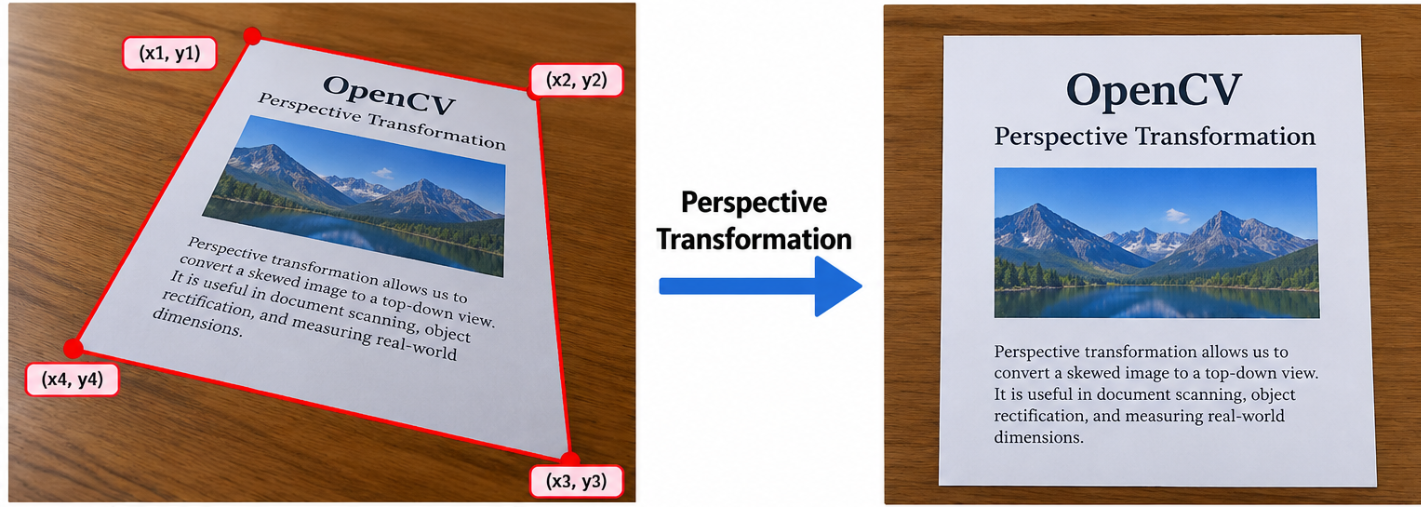 , 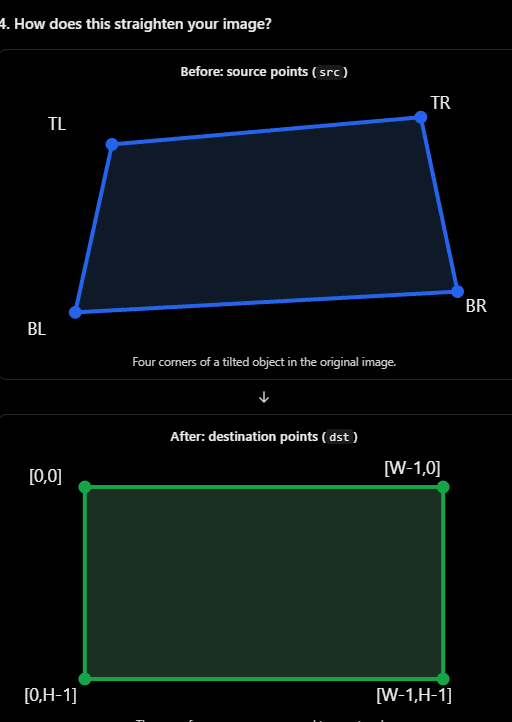

In [ ]:
import numpy as np 

image=cv.resize(cv.imread("IMAGES/perspective.png"),  None ,fx=0.5 ,fy=0.5 , interpolation=cv.INTER_AREA )

original=image.copy()

points=[]

def click(event , x , y , flags , param):
    if event==cv.EVENT_LBUTTONDOWN and len(points)<4:
        points.append([x,y])
        cv.circle(image , (x,y), 5 , (0,0,255),-1)
        cv.imshow("Select Corners:" ,image)

cv.imshow("Select Corners:",image)
cv.setMouseCallback("Select Corners:",click)
print("CLick Corners in order: TL , TR , BR , BL")

while len(points)<4:
    if cv.waitKey(20)==27:
        cv.destroyAllWindows()

src=np.float32(points)

tl , tr , br , bl=src
width=int(max(np.linalg.norm(tr-tl) , np.linalg.norm(br-bl)))
height=int(max(np.linalg.norm(bl-tl), np.linalg.norm(br-tr)))
print("Width",width)
print("Height",height)

dst=np.float32([
    [0,0],
    [width -1 , 0],
    [width -1 , height -1],
    [0, height-1]
])

print("distance",dst)

matrix=cv.getPerspectiveTransform(src , dst)
warped=cv.warpPerspective(original , matrix ,(width , height))
cv.imshow("Perspective Transform", warped)
cv.waitKey(0)
cv.destroyAllWindows()


CLick Corners in order: TL , TR , BR , BL
Width 350
Height 160
distance [[  0.   0.]
 [349.   0.]
 [349. 159.]
 [  0. 159.]]


# 5. Feature Detection

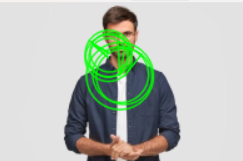

In [24]:
import cv2 as cv 

image=cv.resize(cv.imread("IMAGES/p2.png"),None , fx=0.3 , fy=0.3 , interpolation=cv.INTER_AREA)

gray=cv.cvtColor(image , cv.COLOR_BGR2GRAY)

orb=cv.ORB_create(nfeatures=10)

keypoints=orb.detect(gray , None)

result=cv.drawKeypoints(image , keypoints , None , color=(0,255,0), flags=cv.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)


cv.imshow("image",result)
cv.waitKey()
cv.destroyAllWindows()

# 5.1 HOMOGRAPGHY AND RANSAC

### 5.1.1- WITH ORB_CREATE

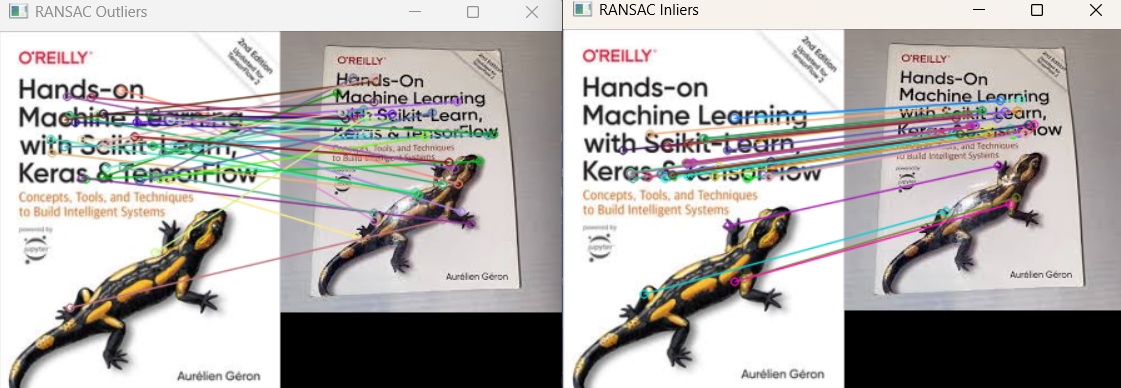

In [73]:
import numpy as np
import cv2 as cv

# 1. Load and resize images
image1 = cv.resize(
    cv.imread("IMAGES/b5.png"),
    None, fx=1, fy=1,
    interpolation=cv.INTER_AREA
)

image2 = cv.resize(
    cv.imread("IMAGES/b6.png"),
    None, fx=1, fy=1,
    interpolation=cv.INTER_AREA
)

if image1 is None or image2 is None:
    raise ValueError("Could not load images")

# 2. Convert to grayscale
gray1 = cv.cvtColor(image1, cv.COLOR_BGR2GRAY)
gray2 = cv.cvtColor(image2, cv.COLOR_BGR2GRAY)

# 3. Detect keypoints and descriptors
orb = cv.ORB_create(nfeatures=300)

ky1, des1 = orb.detectAndCompute(gray1, None)
ky2, des2 = orb.detectAndCompute(gray2, None)

if des1 is None or des2 is None:
    raise ValueError("No descriptors found")

# 4. Match descriptors
bf = cv.BFMatcher(cv.NORM_HAMMING)
pairs = bf.knnMatch(des1, des2, k=2)

# 5. Filter matches using the ratio test
good_matches = []

for pair in pairs:
    if len(pair) == 2:
        m, n = pair

        if m.distance < 0.90 * n.distance:
            good_matches.append(m)

good_matches.sort(key=lambda m: m.distance)

print(f"Keypoints: {len(ky1)} / {len(ky2)}")
print(f"Good matches (ratio=0.75): {len(good_matches)}")

# 6. Check whether enough matches exist
if len(good_matches) < 4:
    raise ValueError("Need at least 4 matches for homography")

# 7. Get corresponding coordinates
pos1 = np.float32([ky1[m.queryIdx].pt for m in good_matches]).reshape(-1, 1, 2)

pos2 = np.float32([ky2[m.trainIdx].pt for m in good_matches]).reshape(-1, 1, 2)

# 8. Estimate homography using RANSAC
H, mask = cv.findHomography(pos1, pos2, cv.RANSAC, 5.0)

if H is None or mask is None:
    raise ValueError("Homography estimation failed")

# 9. Separate inliers and outliers
inliers = [
    m for m, keep in zip(good_matches, mask.ravel())
    if keep
]

outliers = len(good_matches) - len(inliers)

print(f"Inliers: {len(inliers)}  Outliers: {outliers}  "
      f"({100 * len(inliers) / len(good_matches):.1f}% inlier ratio)")

# 10. Draw only inliers
result = cv.drawMatches(
    image1, ky1,
    image2, ky2,
    inliers, None,
    flags=cv.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

outlier_matches = [
    m for m, keep in zip(good_matches, mask.ravel())
    if not keep
]

outlier_result = cv.drawMatches(
    image1, ky1,
    image2, ky2,
    outlier_matches, None,
    flags=cv.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

cv.imshow("WITH ORB RANSAC Inliers", result)
cv.imshow("WITH ORB RANSAC Outliers", outlier_result)

cv.waitKey(0)
cv.destroyAllWindows()



Keypoints: 292 / 263
Good matches (ratio=0.75): 90
Inliers: 41  Outliers: 49  (45.6% inlier ratio)


### 5.1.2 - WITH SIFT_CREATE

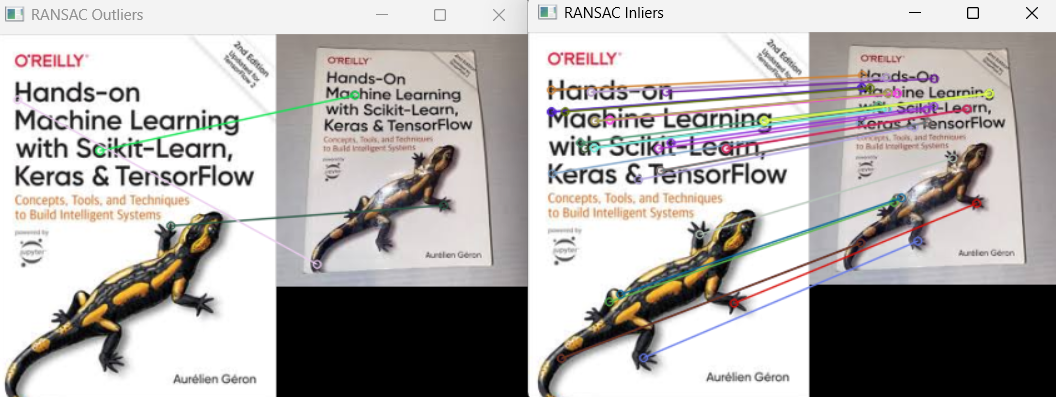

In [77]:
import numpy as np
import cv2 as cv

# 1. Load and resize images
image1 = cv.resize(cv.imread("IMAGES/b5.png"),None, fx=1.5, fy=1.5,interpolation=cv.INTER_AREA)

image2 = cv.resize(cv.imread("IMAGES/b6.png"),None, fx=1.5, fy=1.5,interpolation=cv.INTER_AREA)

if image1 is None or image2 is None:
    raise ValueError("Could not load images")

# 2. Convert to grayscale
gray1 = cv.cvtColor(image1, cv.COLOR_BGR2GRAY)
gray2 = cv.cvtColor(image2, cv.COLOR_BGR2GRAY)

# 3. Detect keypoints and descriptors
orb = cv.SIFT_create(nfeatures=300)

ky1, des1 = orb.detectAndCompute(gray1, None)
ky2, des2 = orb.detectAndCompute(gray2, None)

if des1 is None or des2 is None:
    raise ValueError("No descriptors found")

# 4. Match descriptors
bf = cv.BFMatcher(cv.NORM_L2)
pairs = bf.knnMatch(des1, des2, k=2)

# 5. Filter matches using the ratio test
good_matches = []

for pair in pairs:
    if len(pair) == 2:
        m, n = pair

        if m.distance < 0.75 * n.distance:
            good_matches.append(m)

good_matches.sort(key=lambda m: m.distance)

print(f"Keypoints: {len(ky1)} / {len(ky2)}")
print(f"Good matches (ratio=0.75): {len(good_matches)}")

# 6. Check whether enough matches exist
if len(good_matches) < 4:
    raise ValueError("Need at least 4 matches for homography")

# 7. Get corresponding coordinates
pos1 = np.float32([ky1[m.queryIdx].pt for m in good_matches]).reshape(-1, 1, 2)

pos2 = np.float32([ky2[m.trainIdx].pt for m in good_matches]).reshape(-1, 1, 2)

# 8. Estimate homography using RANSAC
H, mask = cv.findHomography(pos1, pos2, cv.RANSAC, 5.0)

if H is None or mask is None:
    raise ValueError("Homography estimation failed")

# 9. Separate inliers and outliers
inliers = [
    m for m, keep in zip(good_matches, mask.ravel())
    if keep
]

outliers = len(good_matches) - len(inliers)

print(f"Inliers: {len(inliers)}  Outliers: {outliers}  "
      f"({100 * len(inliers) / len(good_matches):.1f}% inlier ratio)")

# 10. Draw only inliers
result = cv.drawMatches(
    image1, ky1,
    image2, ky2,
    inliers, None,
    flags=cv.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

outlier_matches = [
    m for m, keep in zip(good_matches, mask.ravel())
    if not keep
]

outlier_result = cv.drawMatches(
    image1, ky1,
    image2, ky2,
    outlier_matches, None,
    flags=cv.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

cv.imshow("WITH SIFT RANSAC Inliers", result)
cv.imshow("WITH SIFT RANSAC Outliers", outlier_result)

cv.waitKey(0)
cv.destroyAllWindows()

Keypoints: 301 / 301
Good matches (ratio=0.75): 95
Inliers: 66  Outliers: 29  (69.5% inlier ratio)
